# Metode Morphology pada Pengolahan Citra Digital

---

## 1. Pendahuluan Morphology

Morphology adalah teknik pengolahan citra yang berbasis **bentuk (shape)** objek. Operasi morfologi umumnya diterapkan pada **citra biner**, namun juga dapat diperluas pada citra grayscale.

Tujuan utama:

* Menghilangkan noise
* Memperbaiki bentuk objek
* Ekstraksi fitur bentuk
* Segmentasi objek

---

## 2. Contoh Citra Biner

Citra biner hanya memiliki dua nilai piksel:

* 1 (Putih / objek)
* 0 (Hitam / background)

Contoh matriks biner:

```
0 0 0 0 0
0 1 1 1 0
0 1 1 1 0
0 0 0 0 0
```

---

## 3. Konektivitas Piksel

### 4-Connectivity

Tetangga piksel:

* atas
* bawah
* kiri
* kanan

### 8-Connectivity

Termasuk diagonal:

* kiri atas
* kanan atas
* kiri bawah
* kanan bawah

Digunakan untuk analisis komponen terhubung.

---

## 4. Operator Aditif dan Subtraktif

### Operator Aditif

Menambahkan piksel objek.
Contoh: **Dilasi**

### Operator Subtraktif

Mengurangi piksel objek.
Contoh: **Erosi**

---

## 5. Himpunan Translasi dan Refleksi

### Translasi

Perpindahan posisi himpunan piksel:

A + z = {a + z | a ∈ A}

### Refleksi

Pembalikan structuring element terhadap origin.

B^ = {-b | b ∈ B}

Digunakan dalam formulasi umum operasi morfologi.

---

## 6. Elemen Penstruktur (Structuring Element) B

Structuring Element (SE) adalah kernel kecil yang menentukan operasi morfologi.

Contoh:

```
1 1 1
1 1 1
1 1 1
```

Jenis umum:

* Square
* Disk
* Cross
* Line

---

## 7. Dilasi (Dilation)

Dilasi memperbesar objek.

Rumus:

A ⊕ B = { z | (B^)z ∩ A ≠ ∅ }

### Implementasi Python


In [20]:
import cv2
import numpy as np

img = cv2.imread('image.png',0)
_, binary = cv2.threshold(img,127,255,cv2.THRESH_BINARY)

kernel = np.ones((3,3),np.uint8)
dilation = cv2.dilate(binary,kernel,iterations=1)


libpng warning: iCCP: extra compressed data


---

## 8. Erosi (Erosion)

Erosi mengecilkan objek.

Rumus:

A ⊖ B = { z | Bz ⊆ A }


In [21]:
erosion = cv2.erode(binary,kernel,iterations=1)


---

## 9. Opening Operator

Opening = Erosi → Dilasi

Fungsi:

* Menghilangkan noise kecil
* Memisahkan objek tipis


In [22]:
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)

---

## 10. Closing Operator

Closing = Dilasi → Erosi

Fungsi:

* Menutup lubang kecil
* Menyatukan objek berdekatan


In [23]:
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)


---

## 11. Template Matching Morphology

Template matching morfologi digunakan untuk mendeteksi pola tertentu menggunakan structuring element khusus.

Contoh penggunaan:

* Deteksi bentuk huruf
* Deteksi sudut


In [24]:
# Mendefinisikan template yang ingin dicari di dalam citra binary
# Contoh: mengambil potongan kecil (ROI) dari objek atau pola ukuran tertentu
h, w = binary.shape
template = binary[h//4:h//4+30, w//4:w//4+30]

# Melakukan template matching
result = cv2.matchTemplate(binary, template, cv2.TM_CCOEFF)


---

## 12. Hit-or-Miss Transform

Operator untuk mendeteksi pola spesifik pada citra biner.

Rumus:

A ⊗ B = (A ⊖ B1) ∩ (Ac ⊖ B2)

Digunakan untuk:

* Deteksi ujung garis
* Deteksi sudut
* Skeleton analysis


In [25]:
# Kernel khusus Hit-or-Miss (berisi 1, 0, -1) bertipe int8
kernel_hitmiss = np.array([[1, 1, 1], [0, 1, 0], [-1, -1, -1]], dtype=np.int8)
hitmiss = cv2.morphologyEx(binary, cv2.MORPH_HITMISS, kernel_hitmiss)


---

## 13. Boundary Extraction

Mengambil batas objek.

Rumus:

Boundary(A) = A − (A ⊖ B)


In [26]:
# Gunakan structuring element biner (uint8) untuk erosi dan boundary extraction
kernel = np.ones((3, 3), np.uint8)
eroded = cv2.erode(binary, kernel)

# cv2.subtract mencegah underflow modulo 256 pada tipe uint8 (setara A - (A ⊖ B))
boundary = cv2.subtract(binary, eroded)


---

## 14. Thinning

Mengurangi objek menjadi skeleton tanpa merusak struktur.

Digunakan pada:

* OCR
* Fingerprint recognition
* Analisis bentuk


In [27]:
try:
    import cv2.ximgproc as ximgproc
    thin = ximgproc.thinning(binary)
except (ImportError, AttributeError):
    # Fallback menggunakan skeletonize dari skimage jika cv2.ximgproc tidak tersedia
    from skimage.morphology import skeletonize
    thin = (skeletonize(binary > 0) * 255).astype(np.uint8)


---

## 15. Contoh Workflow Lengkap Morphology


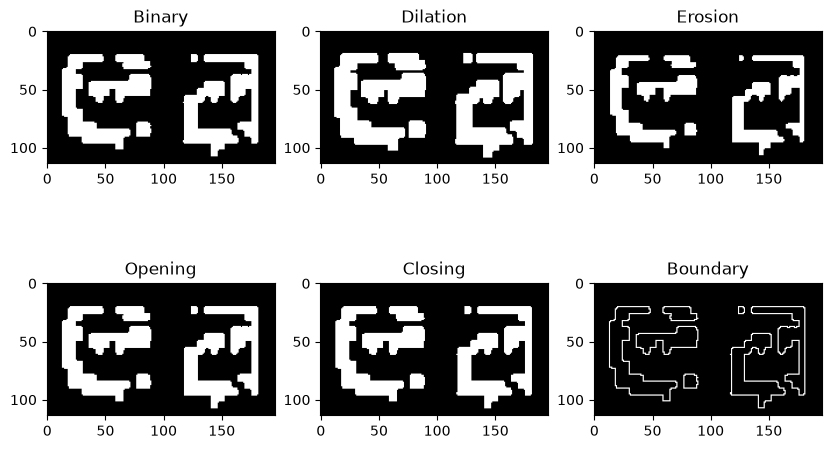

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.subplot(231); plt.imshow(binary, cmap='gray'); plt.title('Binary')
plt.subplot(232); plt.imshow(dilation, cmap='gray'); plt.title('Dilation')
plt.subplot(233); plt.imshow(erosion, cmap='gray'); plt.title('Erosion')
plt.subplot(234); plt.imshow(opening, cmap='gray'); plt.title('Opening')
plt.subplot(235); plt.imshow(closing, cmap='gray'); plt.title('Closing')
plt.subplot(236); plt.imshow(boundary, cmap='gray'); plt.title('Boundary')
plt.show()


---

## 16. Ringkasan Operasi Morphology

| Operasi             | Fungsi            |
| ------------------- | ----------------- |
| Dilasi              | Memperbesar objek |
| Erosi               | Mengecilkan objek |
| Opening             | Hapus noise kecil |
| Closing             | Tutup lubang      |
| Hit-or-Miss         | Deteksi pola      |
| Boundary Extraction | Ambil tepi objek  |
| Thinning            | Skeletonisasi     |

---


## **Visualisasi Step-by-Step Operasi Morphology**

### **1. Citra Awal (Binary Image)**


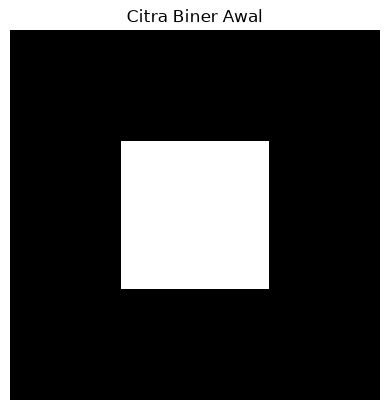

In [29]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Membuat citra biner sederhana
image = np.zeros((10,10), dtype=np.uint8)
image[3:7,3:7] = 255

plt.imshow(image, cmap='gray')
plt.title('Citra Biner Awal')
plt.axis('off')
plt.show()


---

### **2. Structuring Element (Elemen Penstruktur)**


In [30]:
kernel = np.ones((3,3), np.uint8)
print(kernel)


[[1 1 1]
 [1 1 1]
 [1 1 1]]


Mahasiswa dapat mencoba ukuran kernel berbeda:

* 3×3
* 5×5
* bentuk cross

---

### **3. Dilasi (Step-by-Step)**


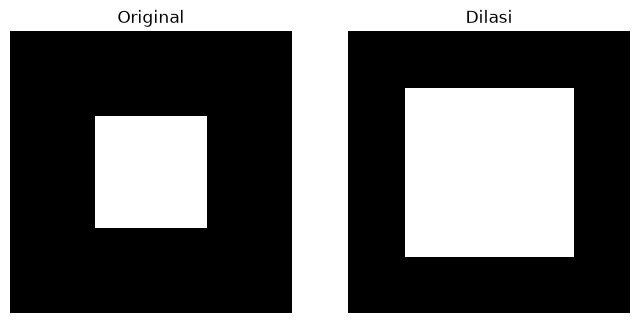

In [31]:
dilation = cv2.dilate(image, kernel, iterations=1)

plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
plt.imshow(image, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(dilation, cmap='gray')
plt.title('Dilasi')
plt.axis('off')
plt.show()


**Observasi:**

* Objek menjadi lebih besar
* Lubang kecil tertutup

---

### **4. Erosi (Step-by-Step)**


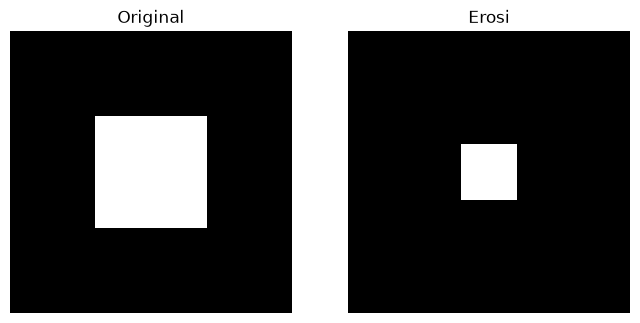

In [32]:
erosion = cv2.erode(image, kernel, iterations=1)

plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
plt.imshow(image, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(erosion, cmap='gray')
plt.title('Erosi')
plt.axis('off')
plt.show()


**Observasi:**

* Objek mengecil
* Noise kecil hilang

---

### **5. Opening (Erosi → Dilasi)**


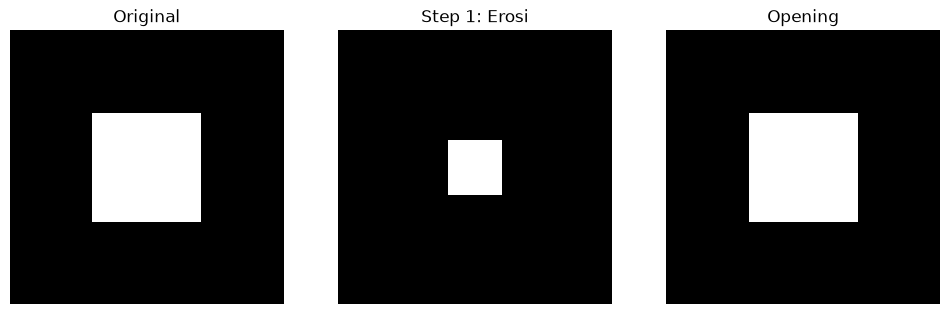

In [33]:
opening = cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)

plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
plt.imshow(image, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(erosion, cmap='gray')
plt.title('Step 1: Erosi')
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(opening, cmap='gray')
plt.title('Opening')
plt.axis('off')
plt.show()


**Fungsi:** Menghilangkan noise kecil tanpa merusak bentuk utama objek.

---

### **6. Closing (Dilasi → Erosi)**


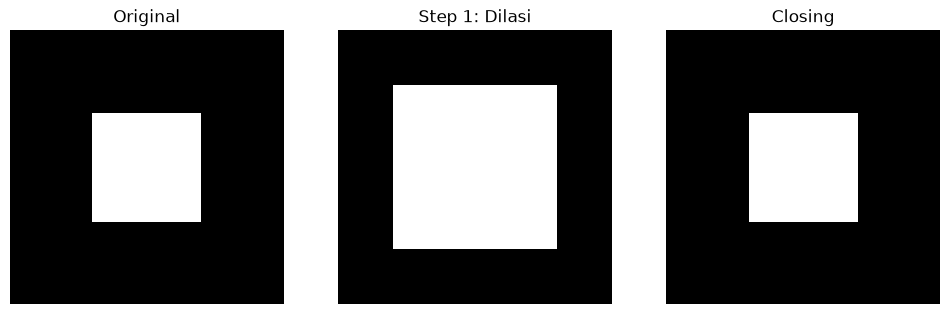

In [34]:
closing = cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)

plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
plt.imshow(image, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(dilation, cmap='gray')
plt.title('Step 1: Dilasi')
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(closing, cmap='gray')
plt.title('Closing')
plt.axis('off')
plt.show()


**Fungsi:** Menutup celah atau lubang kecil pada objek.

---

### **7. Boundary Extraction**


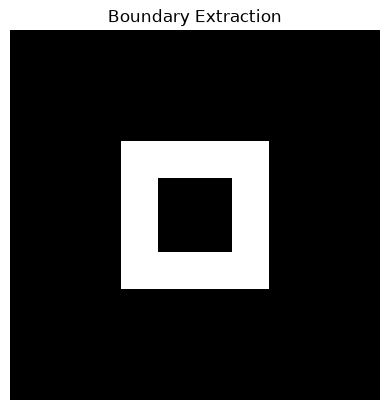

In [35]:
boundary = image - erosion

plt.imshow(boundary, cmap='gray')
plt.title('Boundary Extraction')
plt.axis('off')
plt.show()


Menampilkan hanya batas objek.

---

### **8. Thinning (Skeletonization)**


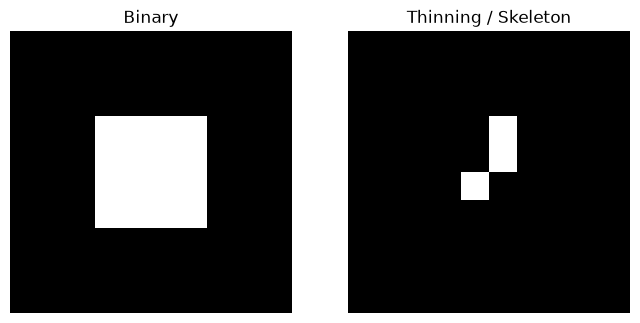

In [36]:
from skimage.morphology import skeletonize

binary = image > 0
skeleton = skeletonize(binary)

plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
plt.imshow(binary, cmap='gray')
plt.title('Binary')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(skeleton, cmap='gray')
plt.title('Thinning / Skeleton')
plt.axis('off')
plt.show()


Menghasilkan representasi rangka objek satu piksel.

---

### **9. Kesimpulan Visualisasi**

* Dilasi memperbesar objek.
* Erosi memperkecil objek.
* Opening efektif untuk menghilangkan noise.
* Closing memperbaiki lubang objek.
* Boundary extraction mengekstrak tepi objek.
* Thinning menghasilkan skeleton untuk analisis bentuk.


## Eksperimen Parameter Structuring Element

### Praktikum Pengolahan Citra Digital

Dokumen ini dapat **langsung di-copy** ke dalam **Jupyter Notebook (.ipynb)**.

---

### 1. Import Library


In [37]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


---

### 2. Membuat Dataset Uji (Binary Image + Noise)


(np.float64(-0.5), np.float64(119.5), np.float64(119.5), np.float64(-0.5))

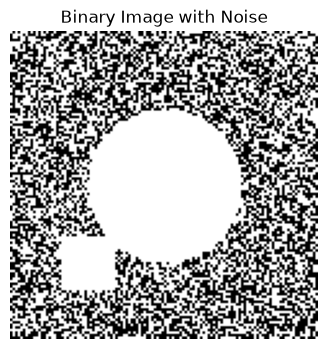

In [38]:
img = np.zeros((120,120), dtype=np.uint8)

# objek utama
cv2.circle(img,(60,60),30,255,-1)
cv2.rectangle(img,(20,80),(40,100),255,-1)

# tambah noise
noise = np.random.randint(0,2,(120,120))*255
img_noisy = cv2.bitwise_or(img, noise.astype(np.uint8))

plt.figure(figsize=(4,4))
plt.imshow(img_noisy, cmap='gray')
plt.title('Binary Image with Noise')
plt.axis('off')


---

### 3. Eksperimen 1 — Variasi Ukuran Structuring Element

Tujuan:

* Mengamati pengaruh ukuran kernel terhadap filtering morphology.


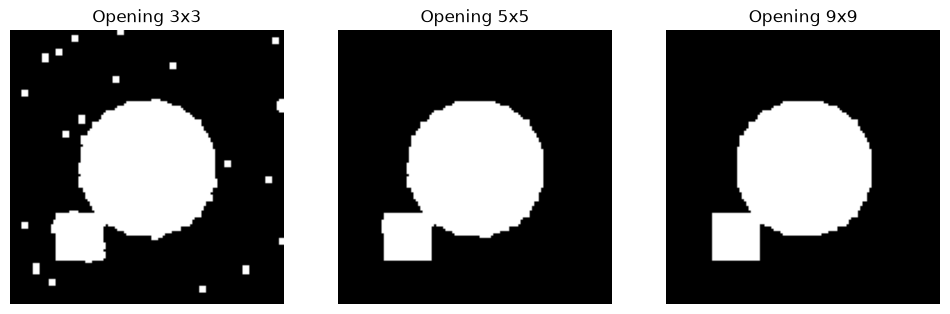

In [39]:
sizes = [3,5,9]

plt.figure(figsize=(12,4))

for i,s in enumerate(sizes):
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT,(s,s))
    result = cv2.morphologyEx(img_noisy, cv2.MORPH_OPEN, kernel)

    plt.subplot(1,3,i+1)
    plt.imshow(result,cmap='gray')
    plt.title(f'Opening {s}x{s}')
    plt.axis('off')

plt.show()


### Observasi

* Kernel kecil → detail tetap
* Kernel besar → noise hilang tetapi objek mengecil

---

### 4. Eksperimen 2 — Variasi Bentuk Structuring Element

Tujuan:

* Memahami pengaruh bentuk SE.


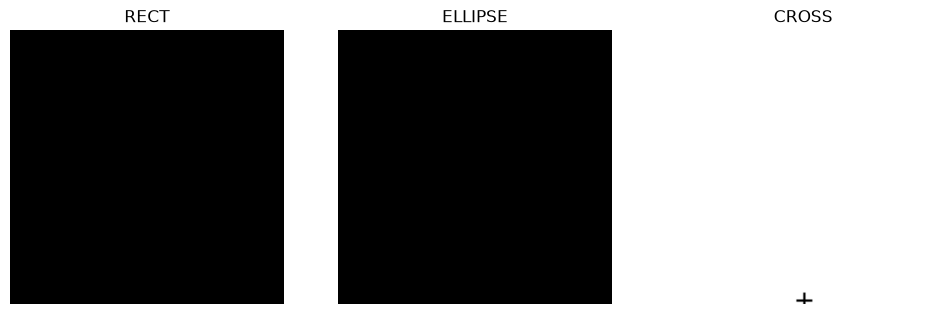

In [40]:
kernels = {
    "RECT": cv2.getStructuringElement(cv2.MORPH_RECT,(7,7)),
    "ELLIPSE": cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(7,7)),
    "CROSS": cv2.getStructuringElement(cv2.MORPH_CROSS,(7,7))
}

plt.figure(figsize=(12,4))

for i,(name,kernel) in enumerate(kernels.items()):
    result = cv2.morphologyEx(img_noisy, cv2.MORPH_CLOSE, kernel)

    plt.subplot(1,3,i+1)
    plt.imshow(result,cmap='gray')
    plt.title(name)
    plt.axis('off')

plt.show()


### Observasi

* RECT → perubahan agresif
* ELLIPSE → bentuk alami objek
* CROSS → menjaga struktur garis

---

### 5. Eksperimen 3 — Dilasi vs Erosi


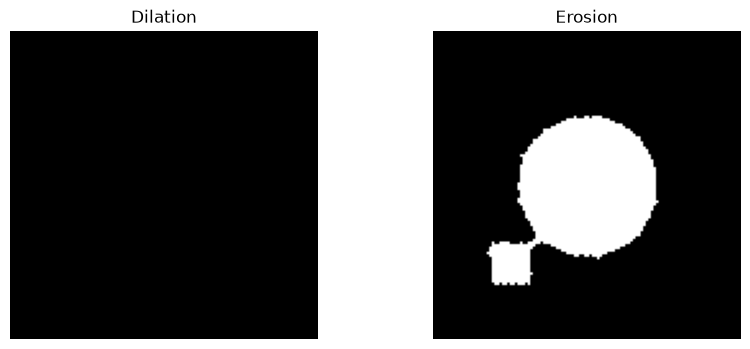

In [41]:
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(7,7))

dilation = cv2.dilate(img_noisy, kernel)
erosion = cv2.erode(img_noisy, kernel)

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.imshow(dilation,cmap='gray')
plt.title('Dilation')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(erosion,cmap='gray')
plt.title('Erosion')
plt.axis('off')

plt.show()


### Observasi

* Dilasi memperbesar objek
* Erosi mengecilkan objek

---

### 6. Eksperimen 4 — Orientasi Structuring Element (Directional Morphology)


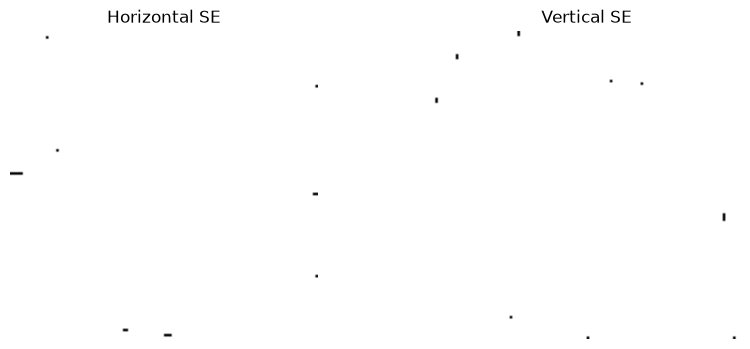

In [42]:
line_kernel = np.zeros((9,9),dtype=np.uint8)
line_kernel[4,:] = 1   # horizontal

horizontal = cv2.dilate(img_noisy, line_kernel)
vertical = cv2.dilate(img_noisy, line_kernel.T)

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.imshow(horizontal,cmap='gray')
plt.title('Horizontal SE')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(vertical,cmap='gray')
plt.title('Vertical SE')
plt.axis('off')

plt.show()


### Insight

Structuring Element dapat bertindak sebagai **Directional Feature Detector**.

---

### 7. Eksperimen 5 — Parameter Sweep (Advanced)

Tujuan:

* Memahami morphology sebagai hyperparameter tuning.


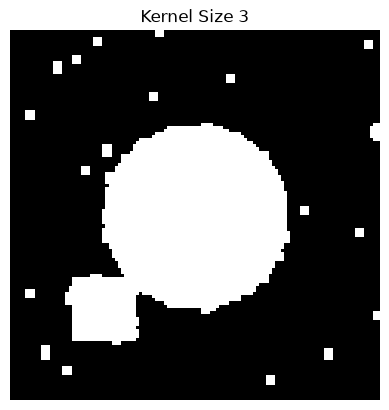

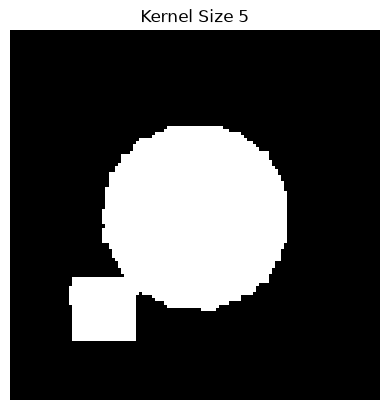

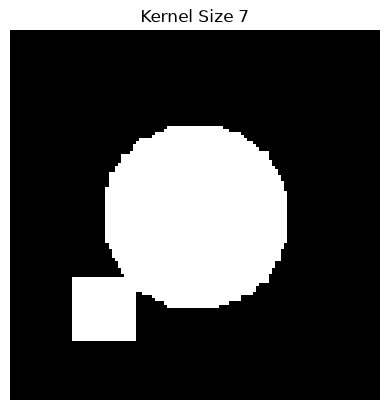

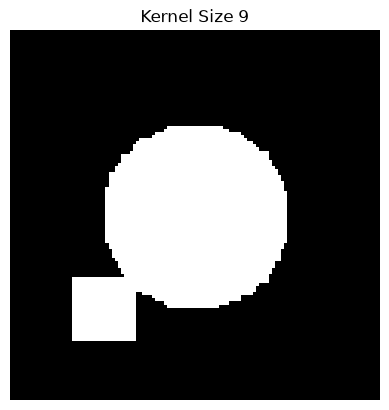

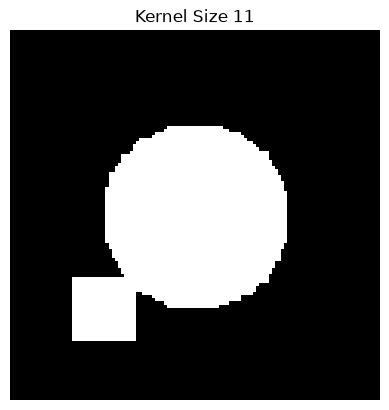

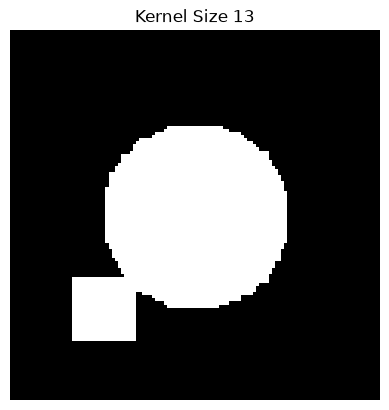

In [43]:
for k in range(3,15,2):
    kernel = np.ones((k,k),np.uint8)
    result = cv2.morphologyEx(img_noisy,
                              cv2.MORPH_OPEN,
                              kernel)

    plt.figure()
    plt.imshow(result,cmap='gray')
    plt.title(f'Kernel Size {k}')
    plt.axis('off')


---

### 8. Kesimpulan Eksperimen

* Structuring Element adalah **hyperparameter utama** pada operasi morphology.
* Ukuran menentukan tingkat filtering spasial.
* Bentuk menentukan sensitivitas terhadap struktur objek.
* Orientasi memungkinkan deteksi fitur arah tertentu.

---


## 9. Eksplorasi

1. **Hole Filling** berbasis dilasi kondisional.  

2. **Geodesic Dilation & Opening by Reconstruction** untuk restorasi bentuk objek asli.  

3. **Top-Hat Transformation pada Citra Grayscale** untuk mengatasi iluminasi tidak merata.  

4. **Morphological Gradient pada Citra Grayscale** untuk ekstraksi kontur/tepi.

---

### 9.1. Hole Filling 

**Konsep Matematika:**
Diberikan sebuah citra biner $X$ yang memiliki lubang (daerah latar belakang yang tertutup oleh piksel latar depan bernilai 1/255).
Algoritma pengisian lubang diawali dengan sebuah titik benih (*seed point*) $p$ di dalam lubang tersebut, dibentuk sebagai citra awal $Y_0$ di mana $Y_0(p) = 1$ dan 0 pada piksel lainnya.

Iterasi pengisian dilakukan dengan mendilasikan $Y_{k-1}$ menggunakan structuring element simetris $B$ (misal cross $3 \times 3$), lalu dibatasi (*constrained*) oleh komplemen citra asli $X^c$:
$$Y_k = (Y_{k-1} \oplus B) \cap X^c, \quad k = 1, 2, 3, \dots$$

Iterasi berhenti ketika konvergen:
$$Y_k = Y_{k-1}$$

Hasil akhir citra dengan lubang terisi penuh diperoleh melalui gabungan (*union*):
$$I_{\text{filled}} = Y_k \cup X$$

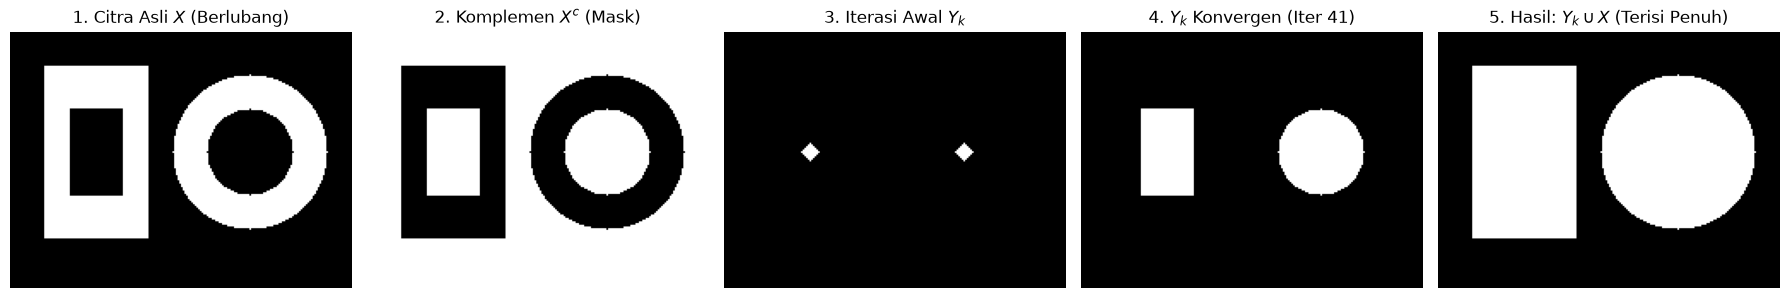

In [45]:
image_size = (150, 200)
X = np.zeros(image_size, dtype=np.uint8)

cv2.rectangle(X, (20, 20), (80, 120), 255, -1)
cv2.rectangle(X, (35, 45), (65, 95), 0, -1)

cv2.circle(X, (140, 70), 45, 255, -1)
cv2.circle(X, (140, 70), 25, 0, -1)

X_c = cv2.bitwise_not(X)

Y = np.zeros_like(X)
Y[70, 50] = 255
Y[70, 140] = 255

B = cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))

history = [Y.copy()]
iterations = 0
max_iter = 500

while iterations < max_iter:
    iterations += 1
    dilated = cv2.dilate(Y, B)
    Y_next = cv2.bitwise_and(dilated, X_c)
    
    if np.array_equal(Y, Y_next):
        break
    Y = Y_next
    if iterations in [5, 15, 30]:
        history.append(Y.copy())

history.append(Y.copy())

X_filled = cv2.bitwise_or(Y, X)

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
axes[0].imshow(X, cmap="gray")
axes[0].set_title("1. Citra Asli $X$ (Berlubang)")
axes[0].axis("off")

axes[1].imshow(X_c, cmap="gray")
axes[1].set_title("2. Komplemen $X^c$ (Mask)")
axes[1].axis("off")

axes[2].imshow(history[1], cmap="gray")
axes[2].set_title("3. Iterasi Awal $Y_k$")
axes[2].axis("off")

axes[3].imshow(Y, cmap="gray")
axes[3].set_title(f"4. $Y_k$ Konvergen (Iter {iterations})")
axes[3].axis("off")

axes[4].imshow(X_filled, cmap="gray")
axes[4].set_title("5. Hasil: $Y_k \cup X$ (Terisi Penuh)")
axes[4].axis("off")

plt.tight_layout()
plt.show()


---

### 9.2. Morphological Reconstruction & Opening by Reconstruction

**Permasalahan pada Operasi Opening Standar:**
Operasi opening standar $(F \circ B = (F \ominus B) \oplus B)$ mampu menghilangkan komponen kecil, namun memiliki kelemahan mendasar: **merusak dan membulatkan geometri sudut objek yang tersisa** karena erosi dan dilasi non-rekursif.

**Solusi: Opening by Reconstruction ($O_R^{(n)}$)**
1. **Marker ($F \ominus nB$):** Citra $F$ dierosi sebanyak $n$ kali. Objek yang lebih kecil atau lebih tipis dari $nB$ akan terhapus seluruhnya, sedangkan objek yang lebih besar menyisakan inti (*marker*).
2. **Mask ($G = F$):** Citra asli digunakan sebagai batas atas (*conditioning mask*).
3. **Geodesic Dilation Terulang ($R_G^D$):** Dilasikan marker secara rekursif dan dibatasi (*bounded*) oleh citra asli:
$$D_G^{(1)}(Y) = (Y \oplus B) \cap G$$
Iterasi dilanjutkan hingga konvergen:
$$O_R^{(n)}(F) = R_F^D(F \ominus nB)$$

**Keunggulan Utama:**
Objek yang bertahan akan dipulihkan secara sempurna ke bentuk dan ukuran aslinya tanpa pembulatan sudut (*exact shape preservation*).

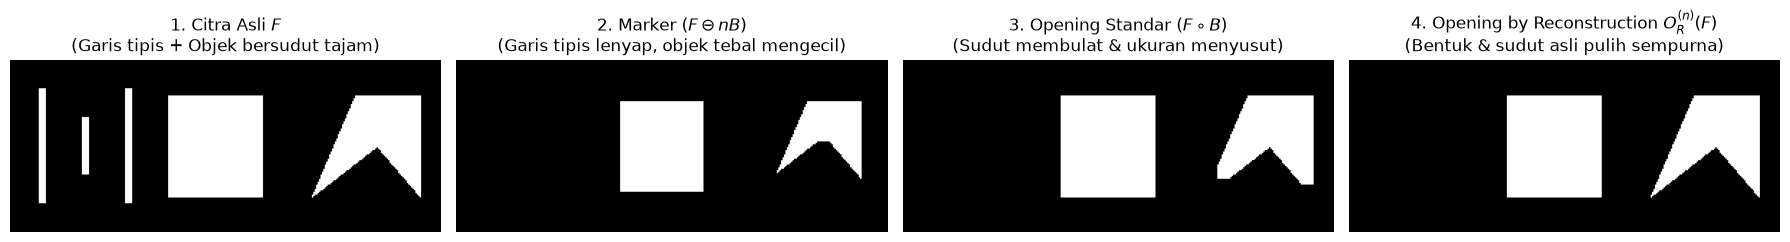

In [46]:
F = np.zeros((120, 300), dtype=np.uint8)

F[20:100, 20:25] = 255
F[40:80, 50:55] = 255
F[20:100, 80:85] = 255

cv2.rectangle(F, (110, 25), (175, 95), 255, -1)

pts = np.array([[210, 95], [240, 25], [285, 25], [285, 95], [255, 60]], np.int32)
cv2.fillPoly(F, [pts], 255)

B_recon = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
kernel_open = cv2.getStructuringElement(cv2.MORPH_RECT, (9, 9))

opening_standard = cv2.morphologyEx(F, cv2.MORPH_OPEN, kernel_open)

marker = cv2.erode(F, B_recon, iterations=4)

mask = F.copy()
recon = marker.copy()

while True:
    recon_next = cv2.dilate(recon, B_recon)
    recon_next = cv2.bitwise_and(recon_next, mask)
    if np.array_equal(recon, recon_next):
        break
    recon = recon_next

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

axes[0].imshow(F, cmap="gray")
axes[0].set_title("1. Citra Asli $F$\n(Garis tipis + Objek bersudut tajam)")
axes[0].axis("off")

axes[1].imshow(marker, cmap="gray")
axes[1].set_title("2. Marker ($F \ominus nB$)\n(Garis tipis lenyap, objek tebal mengecil)")
axes[1].axis("off")

axes[2].imshow(opening_standard, cmap="gray")
axes[2].set_title("3. Opening Standar $(F \circ B)$\n(Sudut membulat & ukuran menyusut)")
axes[2].axis("off")

axes[3].imshow(recon, cmap="gray")
axes[3].set_title("4. Opening by Reconstruction $O_R^{(n)}(F)$\n(Bentuk & sudut asli pulih sempurna)")
axes[3].axis("off")

plt.tight_layout()
plt.show()


---

### 9.3. Top-Hat Transformation pada Citra Grayscale

**Masalah Iluminasi Tidak Rata (Non-Uniform Illumination):**
Pada citra mikroskopis atau fotografi dokumen, pencahayaan sering kali tidak merata. Shading atau gradien latar belakang membuat metode pengambangan global (seperti Otsu) gagal memisahkan objek secara bersih.

**Definisi Top-Hat Transformation:**
* **White Top-Hat:** Mengisolasi elemen terang yang lebih kecil dari structuring element $b$ pada latar belakang bervariasi:
$$T_{\text{hat}}(f) = f - (f \circ b)$$
Di mana $f \circ b$ mengestimasi profil iluminasi latar belakang secara halus tanpa menyertakan objek-objek kecil terang.

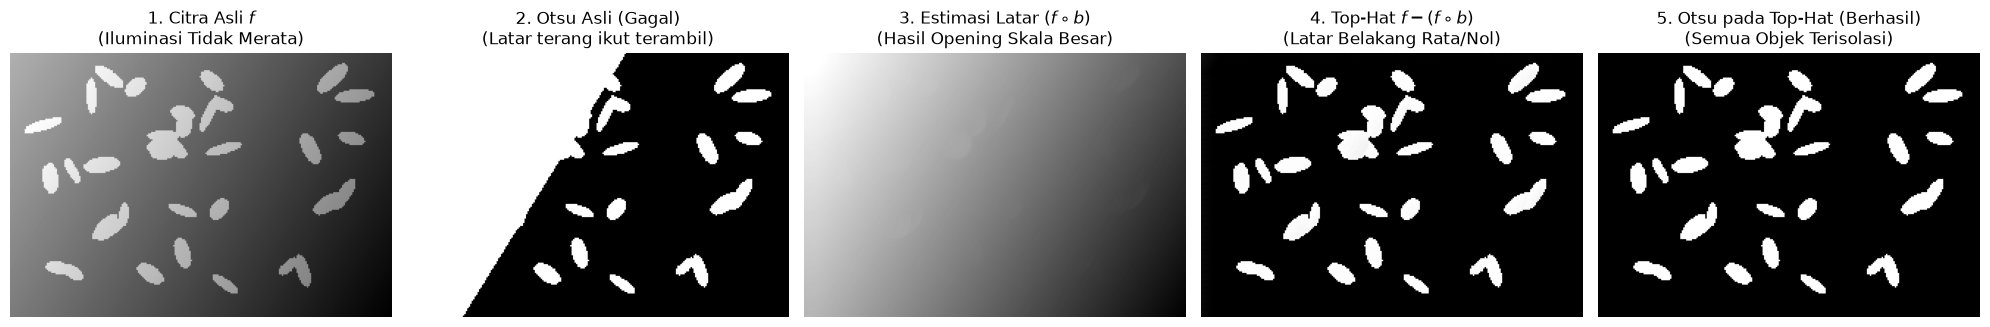

In [47]:
h, w = 180, 260
np.random.seed(42)

y_grad, x_grad = np.ogrid[:h, :w]
background_illumination = (160 * (1 - (x_grad / w) * 0.7 - (y_grad / h) * 0.3)).astype(np.uint8)

objects = np.zeros((h, w), dtype=np.uint8)
for _ in range(35):
    cx = np.random.randint(15, w - 15)
    cy = np.random.randint(15, h - 15)
    axes_len = (np.random.randint(8, 14), np.random.randint(3, 6))
    angle = np.random.randint(0, 180)
    cv2.ellipse(objects, (cx, cy), axes_len, angle, 0, 360, 90, -1)

f_gray = cv2.add(background_illumination, objects)

_, thresh_failed = cv2.threshold(f_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

se_tophat = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (25, 25))
background_estimate = cv2.morphologyEx(f_gray, cv2.MORPH_OPEN, se_tophat)
tophat_result = cv2.morphologyEx(f_gray, cv2.MORPH_TOPHAT, se_tophat)

_, thresh_success = cv2.threshold(tophat_result, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

fig, axes = plt.subplots(1, 5, figsize=(20, 4.2))

axes[0].imshow(f_gray, cmap="gray")
axes[0].set_title("1. Citra Asli $f$\n(Iluminasi Tidak Merata)")
axes[0].axis("off")

axes[1].imshow(thresh_failed, cmap="gray")
axes[1].set_title("2. Otsu Asli (Gagal)\n(Latar terang ikut terambil)")
axes[1].axis("off")

axes[2].imshow(background_estimate, cmap="gray")
axes[2].set_title("3. Estimasi Latar $(f \circ b)$\n(Hasil Opening Skala Besar)")
axes[2].axis("off")

axes[3].imshow(tophat_result, cmap="gray")
axes[3].set_title("4. Top-Hat $f - (f \circ b)$\n(Latar Belakang Rata/Nol)")
axes[3].axis("off")

axes[4].imshow(thresh_success, cmap="gray")
axes[4].set_title("5. Otsu pada Top-Hat (Berhasil)\n(Semua Objek Terisolasi)")
axes[4].axis("off")

plt.tight_layout()
plt.show()


---

### 9.4. Grayscale Morphological Gradient

**Konsep Matematika:**
Gradien morfologi pada citra grayscale menekankan transisi tingkat keabuan tajam (tepi batas objek) secara non-linear:
$$g = (f \oplus b) - (f \ominus b)$$

Variasi gradien morfologi:
* **Morfologi Standar (Basic Gradient):** $g = (f \oplus b) - (f \ominus b)$
* **Internal Gradient:** $g_i = f - (f \ominus b)$ (menghasilkan batas pada sisi dalam objek)
* **External Gradient:** $g_e = (f \oplus b) - f$ (menghasilkan batas pada sisi luar objek)

Keunggulan gradien morfologis dibanding operator turunan linier (seperti Sobel) adalah tidak memperkuat noise frekuensi tinggi secara berlebihan serta menghasilkan batas kontur yang tertutup rapat dan ketebalannya dapat dikontrol melalui ukuran structuring element $b$.

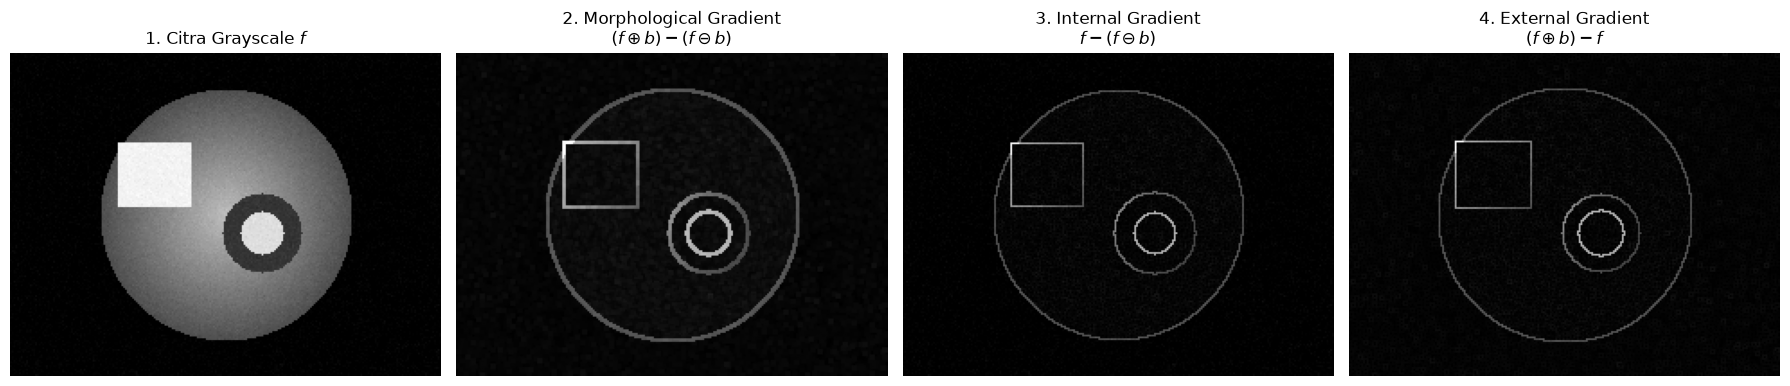

In [48]:
h, w = 180, 240
gray_test = np.zeros((h, w), dtype=np.uint8)

for r in range(h):
    for c in range(w):
        d = np.sqrt((r - 90)**2 + (c - 120)**2)
        if d < 70:
            gray_test[r, c] = int(180 - d * 1.5)

cv2.rectangle(gray_test, (60, 50), (100, 85), 230, -1)
cv2.circle(gray_test, (140, 100), 22, 50, -1)
cv2.circle(gray_test, (140, 100), 12, 210, -1)

np.random.seed(42)
noise = np.random.normal(0, 4, gray_test.shape).astype(np.int16)
gray_noisy = np.clip(gray_test.astype(np.int16) + noise, 0, 255).astype(np.uint8)

b_grad = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

dilated_gray = cv2.dilate(gray_noisy, b_grad)
eroded_gray = cv2.erode(gray_noisy, b_grad)

grad_morph = cv2.morphologyEx(gray_noisy, cv2.MORPH_GRADIENT, b_grad)
grad_internal = cv2.subtract(gray_noisy, eroded_gray)
grad_external = cv2.subtract(dilated_gray, gray_noisy)

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

axes[0].imshow(gray_noisy, cmap="gray")
axes[0].set_title("1. Citra Grayscale $f$")
axes[0].axis("off")

axes[1].imshow(grad_morph, cmap="gray")
axes[1].set_title("2. Morphological Gradient\n$(f \oplus b) - (f \ominus b)$")
axes[1].axis("off")

axes[2].imshow(grad_internal, cmap="gray")
axes[2].set_title("3. Internal Gradient\n$f - (f \ominus b)$")
axes[2].axis("off")

axes[3].imshow(grad_external, cmap="gray")
axes[3].set_title("4. External Gradient\n$(f \oplus b) - f$")
axes[3].axis("off")

plt.tight_layout()
plt.show()


---

### 9.5. Ringkasan & Analisis Eksperimen Morfologi Lanjutan

Berdasarkan implementasi 4 teknik morfologi lanjutan dari materi kuliah Gonzalez & Woods:

1. **Hole Filling (Pengisian Lubang):**
   * Menggunakan konsep **Geodesic Dilation** bersyarat $Y_k = (Y_{k-1} \oplus B) \cap X^c$.
   * Menjamin pengisian hanya terjadi di dalam batas kontur tertutup tanpa bocor ke luar batas objek.
   * Sangat bermanfaat untuk segmentasi sel/biomedis, inspeksi cacat material (*crack/void detection*), serta penyempurnaan mask biner.

2. **Opening by Reconstruction:**
   * Menyelesaikan kelemahan utama operasi opening standar yang cenderung membulatkan sudut dan menyusutkan luas objek.
   * Memulihkan secara sempurna geometri asli (*exact shape recovery*) dari semua komponen yang lolos dari erosi marker.

3. **Top-Hat Transformation:**
   * Berfungsi sebagai filter perata latar belakang (*background flattening filter*).
   * Menghilangkan variasi iluminasi global / pencahayaan tidak merata sehingga metode thresholding sederhana (seperti Otsu) dapat bekerja secara optimal.

4. **Morphological Gradient:**
   * Merupakan alternatif non-linear untuk deteksi tepi citra grayscale.
   * Menghasilkan batas kontur yang tertutup rapat, stabil, dan tebalnya dapat diatur melalui ukuran structuring element $b$.